# SENTINEL-X: AI Early-Warning Chain

## IBM Z Datathon 2026 | IBM LinuxONE

# Connecting weak signals before critical incidents escalate

## Project Overview

SENTINEL-X is a cybersecurity early-warning prototype designed to correlate suspicious signals across authentication, API activity, business transactions, and resource-access events.

Instead of examining each event independently, the prototype looks for related signals across systems within a time window and produces explainable candidate alerts.

# Objectives

- Analyze events from multiple security-related sources.
- Identify combinations of suspicious signals.
- Correlate related activity by account and time window.
- Present evidence that helps explain why an alert was generated.
- Demonstrate execution in the IBM LinuxONE environment.

## Implementation status: The current notebook demonstrates dataset analysis and a rule-based correlation prototype.

In [21]:
import sys
import platform
import os
from datetime import datetime, timezone

print("=" * 60)
print("SENTINEL-X | AI EARLY-WARNING CHAIN")
print("=" * 60)
print("UTC time:", datetime.now(timezone.utc).isoformat())
print("Python:", sys.version.split()[0])
print("Architecture:", platform.machine())
print("Working directory:", os.getcwd())

if platform.machine() == "s390x":
    print("STATUS: Running on IBM LinuxONE architecture")
else:
    print("STATUS: Verify the execution environment")

SENTINEL-X | AI EARLY-WARNING CHAIN
UTC time: 2026-10-17T12:50:28.992067+00:00
Python: 3.12.15
Architecture: s390x
Working directory: /home/ibm-user
STATUS: Running on IBM LinuxONE architecture


# 1. Execution Environment

The prototype is executed in JupyterLab on an IBM LinuxONE environment.

The environment check records the Python version, operating system, machine architecture, and execution time. This helps establish the environment in which the notebook code runs.

Purpose: Verify the execution environment before loading and analyzing the datasets.

In [22]:
from pathlib import Path
import csv

DATA_DIR = Path.cwd()

required_files = [
    "events_master.csv",
    "auth_events.csv",
    "business_events.csv",
    "api_events.csv",
    "resource_events.csv",
]

print("Dataset directory:", DATA_DIR)
print()

for filename in required_files:
    path = DATA_DIR / filename
    if path.exists():
        with path.open("r", encoding="utf-8-sig", newline="") as f:
            reader = csv.reader(f)
            headers = next(reader, [])
            print(f"FOUND: {filename}")
            print("  Columns:", headers)
    else:
        print(f"MISSING: {filename}")

Dataset directory: /home/ibm-user

FOUND: events_master.csv
  Columns: ['event_id', 'timestamp', 'source_system', 'event_type', 'user_id', 'account_id', 'device_id', 'source_ip', 'authentication_result', 'failed_attempt_count', 'geo_region', 'event_severity', 'risk_indicator', 'ground_truth_label', 'scenario_id', 'incident_id', 'transaction_id', 'beneficiary_id', 'transaction_amount', 'currency', 'transaction_status', 'api_client_id', 'endpoint', 'http_method', 'http_status_code', 'response_time_ms', 'resource_id', 'access_type', 'bytes_transferred']
FOUND: auth_events.csv
  Columns: ['event_id', 'timestamp', 'source_system', 'event_type', 'user_id', 'account_id', 'device_id', 'source_ip', 'authentication_result', 'failed_attempt_count', 'geo_region', 'event_severity', 'risk_indicator', 'ground_truth_label', 'scenario_id', 'incident_id']
FOUND: business_events.csv
  Columns: ['event_id', 'timestamp', 'source_system', 'event_type', 'user_id', 'account_id', 'transaction_id', 'beneficiary

# 2. Dataset Discovery and Loading

The project uses synthetic cybersecurity event data representing multiple sources:

- Authentication events
- Business transaction events
- API gateway events
- Resource-access events
- A combined master event dataset
- Ground-truth descriptions for four known incident scenarios

The notebook checks file availability and inspects column names before processing the data.

In [23]:
import pandas as pd

file_paths = {
    "master": DATA_DIR / "events_master.csv",
    "authentication": DATA_DIR / "auth_events.csv",
    "business": DATA_DIR / "business_events.csv",
    "api": DATA_DIR / "api_events.csv",
    "resource": DATA_DIR / "resource_events.csv",
}

datasets = {}

for name, path in file_paths.items():
    if path.exists():
        datasets[name] = pd.read_csv(path)
        print(f"{name}: {datasets[name].shape[0]} rows, "
              f"{datasets[name].shape[1]} columns")
    else:
        print(f"{name}: file not found")

master: 5500 rows, 29 columns
authentication: 1340 rows, 16 columns
business: 1353 rows, 17 columns
api: 1352 rows, 16 columns
resource: 1455 rows, 14 columns


In [24]:
events = datasets["master"]

print("Dataset shape:", events.shape)
print("\nColumn names:")
print(events.columns.tolist())

display(events.head(10))

Dataset shape: (5500, 29)

Column names:
['event_id', 'timestamp', 'source_system', 'event_type', 'user_id', 'account_id', 'device_id', 'source_ip', 'authentication_result', 'failed_attempt_count', 'geo_region', 'event_severity', 'risk_indicator', 'ground_truth_label', 'scenario_id', 'incident_id', 'transaction_id', 'beneficiary_id', 'transaction_amount', 'currency', 'transaction_status', 'api_client_id', 'endpoint', 'http_method', 'http_status_code', 'response_time_ms', 'resource_id', 'access_type', 'bytes_transferred']


,event_id,timestamp,source_system,event_type,user_id,account_id,device_id,source_ip,authentication_result,failed_attempt_count,...,currency,transaction_status,api_client_id,endpoint,http_method,http_status_code,response_time_ms,resource_id,access_type,bytes_transferred
0,EVT-104538,2026-10-17T00:00:33Z,resource,transaction_created,USR_0020,ACC_0002,DEV_0003,192.168.1.13,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,RES_DOC_021,READ,16673.0
1,EVT-102361,2026-10-17T00:00:44Z,business,api_request,USR_0017,ACC_0019,DEV_0009,10.0.4.21,NaN,NaN,...,USD,APPROVED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EVT-102976,2026-10-17T00:01:40Z,business,resource_read,USR_0005,ACC_0010,DEV_0006,192.168.1.27,NaN,NaN,...,USD,APPROVED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EVT-102636,2026-10-17T00:02:05Z,business,resource_read,USR_0002,ACC_0013,DEV_0008,203.0.113.8,NaN,NaN,...,USD,APPROVED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EVT-104121,2026-10-17T00:02:07Z,api_gateway,transaction_created,USR_0008,ACC_0017,DEV_0005,192.168.1.28,NaN,NaN,...,NaN,NaN,API_CLIENT_007,/v1/user/profile,GET,200.0,36.0,NaN,NaN,NaN
5,EVT-104866,2026-10-17T00:02:07Z,api_gateway,transaction_created,USR_0013,ACC_0006,DEV_0011,192.168.1.42,NaN,NaN,...,NaN,NaN,API_CLIENT_009,/v1/user/profile,GET,200.0,61.0,NaN,NaN,NaN
6,EVT-103101,2026-10-17T00:02:22Z,api_gateway,api_request,USR_0006,ACC_0023,DEV_0003,192.168.1.15,NaN,NaN,...,NaN,NaN,API_CLIENT_002,/v1/user/profile,GET,200.0,60.0,NaN,NaN,NaN
7,EVT-100755,2026-10-17T00:02:37Z,resource,resource_permission_denied,USR_0022,ACC_0021,DEV_0006,192.168.1.15,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,RES_DOC_014,READ,0.0
8,EVT-102732,2026-10-17T00:02:40Z,business,login_success,USR_0005,ACC_0016,DEV_0005,192.168.1.28,NaN,NaN,...,USD,APPROVED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,EVT-103817,2026-10-17T00:02:45Z,business,resource_read,USR_0002,ACC_0010,DEV_0011,10.0.4.21,NaN,NaN,...,USD,APPROVED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2.1 Master Dataset Overview

The master CSV consolidates events from different source systems into a common schema.

Each event can include a timestamp, user and account identifiers, event type, source system, severity, risk indicator, and incident-related metadata.

Source-specific fields may be empty when they do not apply to a particular event type. These missing values must be interpreted in the context of the event source.

In [25]:
print("Rows:", len(events))
print("Duplicate event rows:", events.duplicated().sum())

if "event_id" in events.columns:
    print("Duplicate event IDs:", events["event_id"].duplicated().sum())

if "timestamp" in events.columns:
    parsed_time = pd.to_datetime(
        events["timestamp"], errors="coerce", utc=True
    )
    print("Invalid timestamps:", parsed_time.isna().sum())
    print("Earliest timestamp:", parsed_time.min())
    print("Latest timestamp:", parsed_time.max())

print("\nMissing values by column:")
display(events.isna().sum().to_frame("missing_count"))

Rows: 5500
Duplicate event rows: 0
Duplicate event IDs: 0
Invalid timestamps: 0
Earliest timestamp: 2026-10-17 00:00:33+00:00
Latest timestamp: 2026-10-17 23:59:46+00:00

Missing values by column:


,missing_count
event_id,0
timestamp,0
source_system,0
event_type,0
user_id,0
account_id,0
device_id,0
source_ip,0
authentication_result,4085
failed_attempt_count,4085


# 2.2 Data Quality Validation

The notebook checks:

- Total number of records and columns
- Duplicate event records and event IDs
- Timestamp validity
- Missing values in individual columns

These checks help identify data-quality issues before correlation analysis. Missing source-specific attributes do not necessarily indicate invalid records.

In [26]:
print("Events by source system:")

if "source_system" in events.columns:
    display(events["source_system"].value_counts().to_frame("event_count"))
else:
    print("No source_system column. Available columns:")
    print(events.columns.tolist())

Events by source system:


,event_count
source_system,
resource,1455
business,1353
api_gateway,1352
auth,1340


In [27]:
print("Available columns:")
print(events.columns.tolist())

possible_label_columns = [
    "ground_truth_label",
    "label",
    "incident_type",
    "scenario_id",
]

for column in possible_label_columns:
    if column in events.columns:
        print(f"\nDistribution for {column}:")
        display(events[column].value_counts(dropna=False).to_frame("count"))

Available columns:
['event_id', 'timestamp', 'source_system', 'event_type', 'user_id', 'account_id', 'device_id', 'source_ip', 'authentication_result', 'failed_attempt_count', 'geo_region', 'event_severity', 'risk_indicator', 'ground_truth_label', 'scenario_id', 'incident_id', 'transaction_id', 'beneficiary_id', 'transaction_amount', 'currency', 'transaction_status', 'api_client_id', 'endpoint', 'http_method', 'http_status_code', 'response_time_ms', 'resource_id', 'access_type', 'bytes_transferred']

Distribution for ground_truth_label:


,count
ground_truth_label,
benign,4707
isolated_suspicious,550
coordinated_incident,243



Distribution for scenario_id:


,count
scenario_id,
NaN,5257
SCN-API-EXFILTRATION,120
SCN-INSIDER-THREAT,50
SCN-IMPOSSIBLE-TRAVEL,50
SCN-ACCOUNT-TAKEOVER,23


In [28]:
print("=" * 55)
print("EVENT DISTRIBUTION ACROSS SECURITY SYSTEMS")
print("=" * 55)

display(
    events["source_system"]
    .value_counts()
    .rename_axis("Source System")
    .reset_index(name="Total Events")
)

print("\nGround Truth Distribution:")

display(
    events["ground_truth_label"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Total Events")
)

EVENT DISTRIBUTION ACROSS SECURITY SYSTEMS


,Source System,Total Events
0,resource,1455
1,business,1353
2,api_gateway,1352
3,auth,1340



Ground Truth Distribution:


,Category,Total Events
0,benign,4707
1,isolated_suspicious,550
2,coordinated_incident,243


# 3. Exploratory Data Analysis

This section examines the distribution of events across source systems, event types, ground-truth categories, and security-signal labels.

The analysis helps establish the dataset's composition and identify which types of suspicious signals occur most frequently.

Note: Dataset labels describe the synthetic ground truth. They are not predictions produced by the correlation engine.

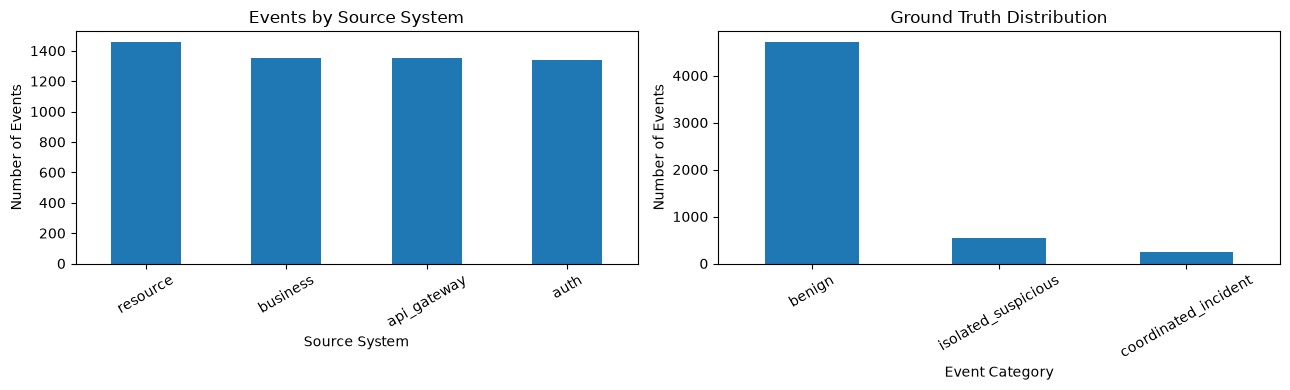

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

events["source_system"].value_counts().plot(
    kind="bar", ax=axes[0], title="Events by Source System"
)
axes[0].set_xlabel("Source System")
axes[0].set_ylabel("Number of Events")
axes[0].tick_params(axis="x", rotation=30)

events["ground_truth_label"].value_counts().plot(
    kind="bar", ax=axes[1], title="Ground Truth Distribution"
)
axes[1].set_xlabel("Event Category")
axes[1].set_ylabel("Number of Events")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [30]:
print("EVENT TYPES BY SOURCE SYSTEM")

event_type_matrix = pd.crosstab(
    events["source_system"],
    events["event_type"]
)

display(event_type_matrix)

print("\nIndividual event types:")
display(events["event_type"].value_counts())

EVENT TYPES BY SOURCE SYSTEM


event_type,api_error,api_gateway_action,api_request,auth_action,beneficiary_added,business_action,login_failure,login_success,new_device_login,resource_action,resource_download,resource_export,resource_permission_denied,resource_read,transaction_created,transaction_rejected
source_system,,,,,,,,,,,,,,,,
api_gateway,36,23,326,0,0,0,32,299,0,0,0,0,31,309,264,32
auth,29,0,318,25,0,0,51,278,1,0,0,0,39,267,299,33
business,32,0,296,0,1,29,33,310,0,0,0,0,42,283,292,35
resource,41,0,303,0,0,0,35,297,0,23,40,5,37,336,311,27



Individual event types:


event_type
api_request                   1243
resource_read                 1195
login_success                 1184
transaction_created           1166
login_failure                  151
resource_permission_denied     149
api_error                      138
transaction_rejected           127
resource_download               40
business_action                 29
auth_action                     25
resource_action                 23
api_gateway_action              23
resource_export                  5
new_device_login                 1
beneficiary_added                1
Name: count, dtype: int64

# 3.1 Ground-Truth Incident Analysis

The dataset includes four documented incident scenarios:

1. Coordinated credential stuffing and account takeover
2. API key compromise and bulk resource data exfiltration
3. Insider threat and privilege escalation
4. Geographic anomaly and rapid resource tampering

The notebook examines the accounts, timestamps, and event evidence associated with these scenarios. Ground-truth information is reserved for evaluation rather than used to generate candidate alerts.

In [31]:
# CELL 12: Coordinated incident ground-truth summary

import pandas as pd

incidents = events[
    events["incident_id"].notna()
    & events["incident_id"].astype(str).str.strip().ne("")
].copy()

# Convert risk indicators to numeric values safely
incidents["risk_indicator"] = pd.to_numeric(
    incidents["risk_indicator"],
    errors="coerce"
)

print("=" * 55)
print("COORDINATED INCIDENT GROUND TRUTH")
print("=" * 55)

print("Events linked to incidents:", len(incidents))
print("Unique incidents:", incidents["incident_id"].nunique())

incident_summary = (
    incidents.groupby("incident_id")
    .agg(
        total_events=("event_id", "count"),
        source_systems=("source_system", "nunique"),
        first_seen=("timestamp", "min"),
        last_seen=("timestamp", "max"),
        average_signal_risk=("risk_indicator", "mean")
    )
    .reset_index()
)

display(incident_summary)

COORDINATED INCIDENT GROUND TRUTH
Events linked to incidents: 243
Unique incidents: 4


,incident_id,total_events,source_systems,first_seen,last_seen,average_signal_risk
0,INC-2026-001,23,3,2026-10-17T02:00:00Z,2026-10-17T02:14:00Z,NaN
1,INC-2026-002,120,2,2026-10-17T06:00:00Z,2026-10-17T06:08:15Z,NaN
2,INC-2026-003,50,4,2026-10-17T12:00:00Z,2026-10-17T12:08:10Z,NaN
3,INC-2026-004,50,4,2026-10-17T18:00:00Z,2026-10-17T18:08:10Z,NaN


In [32]:
if not incidents.empty:
    selected_incident = incidents["incident_id"].iloc[0]

    print("INCIDENT:", selected_incident)

    timeline = (
        incidents[
            incidents["incident_id"] == selected_incident
        ]
        .sort_values("timestamp")
    )

    display(
        timeline[
            [
                "timestamp",
                "source_system",
                "event_type",
                "user_id",
                "risk_indicator",
                "ground_truth_label"
            ]
        ]
    )
else:
    print("No labeled incidents found.")

INCIDENT: INC-2026-001


,timestamp,source_system,event_type,user_id,risk_indicator,ground_truth_label
424,2026-10-17T02:00:00Z,auth,login_failure,USR_0003,NaN,coordinated_incident
425,2026-10-17T02:00:12Z,auth,login_failure,USR_0003,NaN,coordinated_incident
426,2026-10-17T02:00:24Z,auth,login_failure,USR_0003,NaN,coordinated_incident
428,2026-10-17T02:00:36Z,auth,login_failure,USR_0003,NaN,coordinated_incident
429,2026-10-17T02:00:48Z,auth,login_failure,USR_0003,NaN,coordinated_incident
430,2026-10-17T02:01:00Z,auth,login_failure,USR_0003,NaN,coordinated_incident
433,2026-10-17T02:01:12Z,auth,login_failure,USR_0003,NaN,coordinated_incident
434,2026-10-17T02:01:24Z,auth,login_failure,USR_0003,NaN,coordinated_incident
435,2026-10-17T02:01:36Z,auth,login_failure,USR_0003,NaN,coordinated_incident
436,2026-10-17T02:01:48Z,auth,login_failure,USR_0003,NaN,coordinated_incident


In [33]:
# CELL 14: Cross-system incident evidence

required_columns = [
    "incident_id",
    "event_id",
    "timestamp",
    "source_system",
    "event_type",
    "user_id",
    "account_id",
    "risk_indicator",
]

missing = [c for c in required_columns if c not in events.columns]

if missing:
    print("Missing required columns:", missing)
else:
    analysis = events.copy()

    analysis["risk_indicator"] = pd.to_numeric(
        analysis["risk_indicator"], errors="coerce"
    )

    # Ground truth is used only to inspect known incident evidence here.
    known_incident_events = analysis[
        analysis["incident_id"].notna()
        & analysis["incident_id"].astype(str).str.strip().ne("")
    ].copy()

    evidence_summary = (
        known_incident_events
        .groupby("incident_id")
        .agg(
            event_count=("event_id", "nunique"),
            systems_involved=("source_system", "nunique"),
            users_involved=("user_id", "nunique"),
            accounts_involved=("account_id", "nunique"),
            average_event_risk=("risk_indicator", "mean"),
        )
        .reset_index()
        .sort_values(
            ["systems_involved", "event_count"],
            ascending=False
        )
    )

    display(evidence_summary)

,incident_id,event_count,systems_involved,users_involved,accounts_involved,average_event_risk
2,INC-2026-003,50,4,1,1,NaN
3,INC-2026-004,50,4,1,1,NaN
0,INC-2026-001,23,3,1,1,NaN
1,INC-2026-002,120,2,1,1,NaN


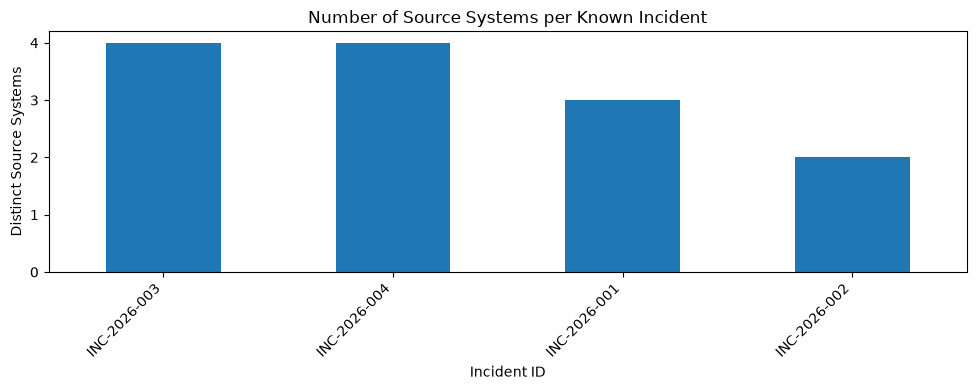

In [34]:
# CELL 15: Visualize known incident evidence

import matplotlib.pyplot as plt

if "evidence_summary" in globals() and not evidence_summary.empty:
    plot_data = evidence_summary.set_index("incident_id")[
        "systems_involved"
    ].sort_values(ascending=False)

    ax = plot_data.plot(kind="bar", figsize=(10, 4))
    ax.set_title("Number of Source Systems per Known Incident")
    ax.set_xlabel("Incident ID")
    ax.set_ylabel("Distinct Source Systems")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No incident evidence summary is available.")

In [35]:
# CELL 16: Locate and inspect ground-truth file

ground_truth_files = list(DATA_DIR.glob("incidents_ground*.csv"))

print("Ground-truth files found:", len(ground_truth_files))

for path in ground_truth_files:
    print("\nFile:", path.name)

    ground_truth = pd.read_csv(path)

    print("Shape:", ground_truth.shape)
    print("Columns:", ground_truth.columns.tolist())

    display(ground_truth.head(10))

Ground-truth files found: 1

File: incidents_ground_truth.csv
Shape: (4, 7)
Columns: ['incident_id', 'scenario_id', 'scenario_name', 'target_user', 'target_account', 'start_time', 'description']


,incident_id,scenario_id,scenario_name,target_user,target_account,start_time,description
0,INC-2026-001,SCN-ACCOUNT-TAKEOVER,Coordinated Credential Stuffing & High-Value D...,USR_0003,ACC_0003,2026-10-17T02:00:00Z,"Failed logins followed by new device login, be..."
1,INC-2026-002,SCN-API-EXFILTRATION,API Key Compromise & Bulk Resource Data Exfilt...,USR_0007,ACC_0007,2026-10-17T06:00:00Z,"Unusual API key usage, rapid 429 rate limit sp..."
2,INC-2026-003,SCN-INSIDER-THREAT,Privilege Escalation & Malicious Beneficiary T...,USR_0012,ACC_0012,2026-10-17T12:00:00Z,"Late night/off-hours login, role elevation API..."
3,INC-2026-004,SCN-IMPOSSIBLE-TRAVEL,Geographic Anomaly & Rapid Resource Tampering,USR_0018,ACC_0018,2026-10-17T18:00:00Z,Login from US-EAST followed 5 minutes later by...


In [36]:
# CELL 17: Diagnose risk indicator values

print("Risk indicator data type:")
print(events["risk_indicator"].dtype)

print("\nSample raw values:")
display(events["risk_indicator"].head(15))

print("\nNumeric conversion check:")
risk_numeric = pd.to_numeric(
    events["risk_indicator"],
    errors="coerce"
)

print("Valid numeric values:", risk_numeric.notna().sum())
print("Missing/invalid values:", risk_numeric.isna().sum())

display(risk_numeric.describe().to_frame("risk_indicator"))

Risk indicator data type:
str

Sample raw values:


0                 NONE
1                 NONE
2                 NONE
3                 NONE
4                 NONE
5                 NONE
6                 NONE
7     ISOLATED_ANOMALY
8                 NONE
9                 NONE
10                NONE
11                NONE
12                NONE
13                NONE
14                NONE
Name: risk_indicator, dtype: str


Numeric conversion check:
Valid numeric values: 0
Missing/invalid values: 5500


,risk_indicator
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


In [37]:
# CELL 18: Inspect ground-truth consistency

for col in ["ground_truth_label", "scenario_id", "incident_id"]:
    print(f"\n{col}:")
    if col in events.columns:
        display(events[col].value_counts(dropna=False).head(15).to_frame("count"))

print("\nIncident IDs in master dataset:")
display(
    events.loc[
        events["incident_id"].notna(),
        ["incident_id", "scenario_id", "ground_truth_label"]
    ].drop_duplicates().sort_values("incident_id")
)


ground_truth_label:


,count
ground_truth_label,
benign,4707
isolated_suspicious,550
coordinated_incident,243



scenario_id:


,count
scenario_id,
NaN,5257
SCN-API-EXFILTRATION,120
SCN-INSIDER-THREAT,50
SCN-IMPOSSIBLE-TRAVEL,50
SCN-ACCOUNT-TAKEOVER,23



incident_id:


,count
incident_id,
NaN,5257
INC-2026-002,120
INC-2026-003,50
INC-2026-004,50
INC-2026-001,23



Incident IDs in master dataset:


,incident_id,scenario_id,ground_truth_label
424,INC-2026-001,SCN-ACCOUNT-TAKEOVER,coordinated_incident
1332,INC-2026-002,SCN-API-EXFILTRATION,coordinated_incident
2716,INC-2026-003,SCN-INSIDER-THREAT,coordinated_incident
4099,INC-2026-004,SCN-IMPOSSIBLE-TRAVEL,coordinated_incident


In [38]:
# CELL 19: Search for existing SENTINEL-X Python modules

from pathlib import Path

search_roots = [
    Path.cwd(),
    Path.home() / "shared",
    Path("/home/jovyan/shared"),
    Path("/home/ibm-user/shared"),
]

for root in search_roots:
    if not root.exists():
        continue

    print(f"\nSearching: {root}")

    for pattern in ["app.py", "requirements.txt", "train_model.py",
                    "run_app.sh", "check_environment.sh"]:
        matches = list(root.glob(f"**/{pattern}"))[:10]
        for match in matches:
            print(match)


Searching: /home/ibm-user

Searching: /home/ibm-user/shared

Searching: /home/jovyan/shared

Searching: /home/ibm-user/shared


In [39]:
from pathlib import Path

root = Path.home()

print("Home directory:", root)
print("\nFiles in home directory:")

for item in sorted(root.iterdir()):
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind}  {item.name}")

Home directory: /home/ibm-user

Files in home directory:
FILE  .bash_logout
FILE  .bash_profile
FILE  .bashrc
DIR   .bashrc.d
DIR   .cache
DIR   .config
DIR   .ipynb_checkpoints
DIR   .ipython
DIR   .jupyter
DIR   .local
FILE  Untitled1.ipynb
FILE  api_events.csv
FILE  auth_events.csv
FILE  business_events.csv
FILE  events_master.csv
DIR   images
FILE  incidents_ground_truth.csv
DIR   loan_demo
FILE  resource_events.csv
DIR   sample_data
DIR   shared


In [40]:
print("Risk indicator values:")
display(events["risk_indicator"].value_counts(dropna=False).to_frame("count"))

print("\nEvent severity values:")
display(events["event_severity"].value_counts(dropna=False).to_frame("count"))

Risk indicator values:


,count
risk_indicator,
NONE,4707
ISOLATED_ANOMALY,550
ANOMALOUS_PATTERN,100
RATE_LIMIT_EXCEEDED,80
BULK_DATA_DOWNLOAD,40
HIGH_FAILED_LOGINS,15
AUDIT_LOG_EXPORT,5
NEW_DEVICE_AFTER_FAILURES,1
NEW_BENEFICIARY_ADDED,1



Event severity values:


,count
event_severity,
LOW,4707
MEDIUM,606
HIGH,186
CRITICAL,1


# 4. Explainable Cross-System Correlation

The prototype assigns configurable heuristic points to selected security-signal categories. It then examines events associated with the same account within a time window.

A candidate alert requires:

- Positive security-signal events
- Activity involving at least two distinct source systems
- A combined signal-point total meeting the configured threshold

Prototype Configuration

- Correlation window: 30 minutes
- Minimum distinct source systems: 2
- Minimum signal points: 3

These values are manually configured prototype rules, not learned model parameters or probabilities of compromise.

In [41]:
# CELL 22: Explainable cross-system correlation prototype

import pandas as pd

correlation_events = events.copy()

# Normalize timestamps and signal fields
correlation_events["timestamp"] = pd.to_datetime(
    correlation_events["timestamp"],
    errors="coerce",
    utc=True
)

correlation_events["source_system"] = (
    correlation_events["source_system"].astype(str).str.lower()
)

correlation_events["risk_indicator"] = (
    correlation_events["risk_indicator"]
    .fillna("NONE")
    .astype(str)
    .str.upper()
)

# Signal weights are prototype design choices, not learned probabilities.
signal_weights = {
    "NONE": 0,
    "ISOLATED_ANOMALY": 1,
    "ANOMALOUS_PATTERN": 2,
    "RATE_LIMIT_EXCEEDED": 2,
    "BULK_DATA_DOWNLOAD": 3,
    "HIGH_FAILED_LOGINS": 2,
    "AUDIT_LOG_EXPORT": 2,
    "NEW_DEVICE_AFTER_FAILURES": 3,
    "NEW_BENEFICIARY_ADDED": 3,
    "HIGH_VALUE_OUTFLOW": 3,
}

correlation_events["signal_points"] = (
    correlation_events["risk_indicator"]
    .map(signal_weights)
    .fillna(0)
)

print("Events loaded:", len(correlation_events))
print("Events with recognized signal categories:",
      correlation_events["risk_indicator"].isin(signal_weights).sum())
print("Total signal points:", correlation_events["signal_points"].sum())

display(
    correlation_events[
        correlation_events["signal_points"] > 0
    ][[
        "timestamp", "source_system", "event_type",
        "user_id", "account_id", "risk_indicator", "signal_points"
    ]].head(15)
)

Events loaded: 5500
Events with recognized signal categories: 5500
Total signal points: 1079


,timestamp,source_system,event_type,user_id,account_id,risk_indicator,signal_points
7,2026-10-17 00:02:37+00:00,resource,resource_permission_denied,USR_0022,ACC_0021,ISOLATED_ANOMALY,1
27,2026-10-17 00:06:35+00:00,auth,login_failure,USR_0024,ACC_0007,ISOLATED_ANOMALY,1
38,2026-10-17 00:09:28+00:00,auth,resource_permission_denied,USR_0017,ACC_0024,ISOLATED_ANOMALY,1
39,2026-10-17 00:10:09+00:00,resource,login_failure,USR_0009,ACC_0006,ISOLATED_ANOMALY,1
55,2026-10-17 00:13:56+00:00,business,login_failure,USR_0014,ACC_0005,ISOLATED_ANOMALY,1
59,2026-10-17 00:14:47+00:00,resource,api_error,USR_0013,ACC_0011,ISOLATED_ANOMALY,1
71,2026-10-17 00:18:29+00:00,api_gateway,api_error,USR_0008,ACC_0009,ISOLATED_ANOMALY,1
90,2026-10-17 00:25:26+00:00,resource,resource_permission_denied,USR_0021,ACC_0006,ISOLATED_ANOMALY,1
123,2026-10-17 00:35:28+00:00,api_gateway,transaction_rejected,USR_0012,ACC_0003,ISOLATED_ANOMALY,1
130,2026-10-17 00:36:53+00:00,auth,login_failure,USR_0013,ACC_0022,ISOLATED_ANOMALY,1


In [42]:
# CELL 23: Time-window correlation

WINDOW_MINUTES = 30
MIN_SOURCES = 2
MIN_SIGNAL_POINTS = 3

candidate_alerts = []

usable = correlation_events.dropna(
    subset=["timestamp", "account_id"]
).sort_values("timestamp")

for account_id, group in usable.groupby("account_id"):
    group = group.reset_index(drop=True)

    for i, row in group.iterrows():
        window_start = row["timestamp"]
        window_end = window_start + pd.Timedelta(
            minutes=WINDOW_MINUTES
        )

        window = group[
            (group["timestamp"] >= window_start)
            & (group["timestamp"] <= window_end)
        ]

        # Ignore windows with no positive security signals.
        signal_events = window[window["signal_points"] > 0]

        if signal_events.empty:
            continue

        source_count = signal_events["source_system"].nunique()
        signal_total = signal_events["signal_points"].sum()

        if (
            source_count >= MIN_SOURCES
            and signal_total >= MIN_SIGNAL_POINTS
        ):
            candidate_alerts.append({
                "account_id": account_id,
                "window_start": window_start,
                "window_end": window_end,
                "event_count": len(signal_events),
                "source_count": source_count,
                "signal_points": int(signal_total),
                "signal_types": ", ".join(
                    sorted(signal_events["risk_indicator"].unique())
                ),
                "event_ids": ", ".join(
                    signal_events["event_id"].astype(str).tolist()
                ),
            })

alerts = pd.DataFrame(candidate_alerts)

if not alerts.empty:
    alerts = alerts.drop_duplicates(
        subset=["account_id", "event_ids"]
    ).sort_values("signal_points", ascending=False)

print("Candidate alert windows:", len(alerts))

if not alerts.empty:
    display(alerts.head(20))
else:
    print("No candidate windows matched the current rules.")

Candidate alert windows: 241


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types,event_ids
43,ACC_0007,2026-10-17 05:48:23+00:00,2026-10-17 06:18:23+00:00,120,2,280,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100024, EVT-100025, EVT-100026, EVT-100027..."
47,ACC_0007,2026-10-17 06:00:03+00:00,2026-10-17 06:30:03+00:00,119,2,278,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100025, EVT-100026, EVT-100027, EVT-100028..."
48,ACC_0007,2026-10-17 06:00:06+00:00,2026-10-17 06:30:06+00:00,118,2,276,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100026, EVT-100027, EVT-100028, EVT-100029..."
49,ACC_0007,2026-10-17 06:00:09+00:00,2026-10-17 06:30:09+00:00,117,2,274,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100027, EVT-100028, EVT-100029, EVT-100030..."
50,ACC_0007,2026-10-17 06:00:12+00:00,2026-10-17 06:30:12+00:00,116,2,272,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100028, EVT-100029, EVT-100030, EVT-100031..."
51,ACC_0007,2026-10-17 06:00:15+00:00,2026-10-17 06:30:15+00:00,115,2,270,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100029, EVT-100030, EVT-100031, EVT-100032..."
52,ACC_0007,2026-10-17 06:00:18+00:00,2026-10-17 06:30:18+00:00,114,2,268,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100030, EVT-100031, EVT-100032, EVT-100033..."
53,ACC_0007,2026-10-17 06:00:21+00:00,2026-10-17 06:30:21+00:00,113,2,266,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100031, EVT-100032, EVT-100033, EVT-100034..."
54,ACC_0007,2026-10-17 06:00:24+00:00,2026-10-17 06:30:24+00:00,112,2,264,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100032, EVT-100033, EVT-100034, EVT-100035..."
55,ACC_0007,2026-10-17 06:00:27+00:00,2026-10-17 06:30:27+00:00,111,2,262,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100033, EVT-100034, EVT-100035, EVT-100036..."


In [43]:
# CELL 24: Evidence for the strongest candidate

if not alerts.empty:
    best = alerts.iloc[0]

    print("CANDIDATE ALERT")
    print("Account:", best["account_id"])
    print("Signal points:", best["signal_points"])
    print("Distinct source systems:", best["source_count"])
    print("Window:", best["window_start"], "to", best["window_end"])
    print("Signal types:", best["signal_types"])

    evidence_ids = best["event_ids"].split(", ")

    evidence = correlation_events[
        correlation_events["event_id"].astype(str).isin(evidence_ids)
    ].sort_values("timestamp")

    display(
        evidence[[
            "timestamp", "event_id", "source_system",
            "event_type", "user_id", "account_id",
            "risk_indicator", "event_severity"
        ]]
    )
else:
    print("No candidate alert is available to explain.")

CANDIDATE ALERT
Account: ACC_0007
Signal points: 280
Distinct source systems: 2
Window: 2026-10-17 05:48:23+00:00 to 2026-10-17 06:18:23+00:00
Signal types: BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED


,timestamp,event_id,source_system,event_type,user_id,account_id,risk_indicator,event_severity
1332,2026-10-17 06:00:00+00:00,EVT-100024,api_gateway,api_request,USR_0007,ACC_0007,RATE_LIMIT_EXCEEDED,MEDIUM
1333,2026-10-17 06:00:03+00:00,EVT-100025,api_gateway,api_request,USR_0007,ACC_0007,RATE_LIMIT_EXCEEDED,MEDIUM
1334,2026-10-17 06:00:06+00:00,EVT-100026,api_gateway,api_request,USR_0007,ACC_0007,RATE_LIMIT_EXCEEDED,MEDIUM
1335,2026-10-17 06:00:09+00:00,EVT-100027,api_gateway,api_request,USR_0007,ACC_0007,RATE_LIMIT_EXCEEDED,MEDIUM
1336,2026-10-17 06:00:12+00:00,EVT-100028,api_gateway,api_request,USR_0007,ACC_0007,RATE_LIMIT_EXCEEDED,MEDIUM
...,...,...,...,...,...,...,...,...
1474,2026-10-17 06:07:55+00:00,EVT-100139,resource,resource_download,USR_0007,ACC_0007,BULK_DATA_DOWNLOAD,HIGH
1475,2026-10-17 06:08:00+00:00,EVT-100140,resource,resource_download,USR_0007,ACC_0007,BULK_DATA_DOWNLOAD,HIGH
1476,2026-10-17 06:08:05+00:00,EVT-100141,resource,resource_download,USR_0007,ACC_0007,BULK_DATA_DOWNLOAD,HIGH
1479,2026-10-17 06:08:10+00:00,EVT-100142,resource,resource_download,USR_0007,ACC_0007,BULK_DATA_DOWNLOAD,HIGH


# 4.1 Candidate Alert Consolidation

A single incident may produce several overlapping candidate windows. The consolidation step merges overlapping windows for the same account to make the results easier to inspect.

The current implementation uses a heuristic consolidation method. The resulting episodes require further validation to establish whether they represent distinct security incidents.

In [44]:
# CELL 25: Consolidate overlapping alert windows

if alerts.empty:
    print("No candidate alerts to consolidate.")
else:
    alerts_sorted = alerts.sort_values(
        ["account_id", "window_start", "window_end"]
    ).reset_index(drop=True)

    consolidated = []
    current = None

    for _, row in alerts_sorted.iterrows():
        if (
            current is not None
            and row["account_id"] == current["account_id"]
            and row["window_start"] <= current["window_end"]
        ):
            current["window_end"] = max(
                current["window_end"], row["window_end"]
            )
            current["event_count"] = max(
                current["event_count"], row["event_count"]
            )
            current["source_count"] = max(
                current["source_count"], row["source_count"]
            )
            current["signal_points"] = max(
                current["signal_points"], row["signal_points"]
            )

            types = set(current["signal_types"].split(", "))
            types.update(row["signal_types"].split(", "))
            current["signal_types"] = ", ".join(sorted(types))

            ids = set(current["event_ids"].split(", "))
            ids.update(row["event_ids"].split(", "))
            current["event_ids"] = ", ".join(sorted(ids))
        else:
            if current is not None:
                consolidated.append(current)

            current = row.to_dict()

    if current is not None:
        consolidated.append(current)

    consolidated_alerts = pd.DataFrame(consolidated)

    print("Original candidate windows:", len(alerts))
    print("Consolidated alert episodes:", len(consolidated_alerts))

    display(
        consolidated_alerts.sort_values(
            "signal_points", ascending=False
        ).head(20)
    )

Original candidate windows: 241
Consolidated alert episodes: 25


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types,event_ids
7,ACC_0007,2026-10-17 05:48:23+00:00,2026-10-17 06:33:57+00:00,120,2,280,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100024, EVT-100025, EVT-100026, EVT-100027..."
12,ACC_0012,2026-10-17 11:37:33+00:00,2026-10-17 12:38:00+00:00,51,4,101,"ANOMALOUS_PATTERN, ISOLATED_ANOMALY","EVT-100144, EVT-100145, EVT-100146, EVT-100147..."
18,ACC_0018,2026-10-17 17:32:53+00:00,2026-10-17 18:38:00+00:00,50,4,100,ANOMALOUS_PATTERN,"EVT-100194, EVT-100195, EVT-100196, EVT-100197..."
2,ACC_0003,2026-10-17 01:31:31+00:00,2026-10-17 02:38:00+00:00,23,3,49,"AUDIT_LOG_EXPORT, HIGH_FAILED_LOGINS, HIGH_VAL...","EVT-100001, EVT-100002, EVT-100003, EVT-100004..."
22,ACC_0021,2026-10-17 16:53:30+00:00,2026-10-17 17:54:44+00:00,6,3,6,ISOLATED_ANOMALY,"EVT-100498, EVT-100502, EVT-100510, EVT-100623..."
15,ACC_0015,2026-10-17 16:54:49+00:00,2026-10-17 17:45:13+00:00,4,3,4,ISOLATED_ANOMALY,"EVT-100377, EVT-100452, EVT-100476, EVT-100538"
3,ACC_0004,2026-10-17 22:47:30+00:00,2026-10-17 23:43:26+00:00,4,4,4,ISOLATED_ANOMALY,"EVT-100294, EVT-100307, EVT-100337, EVT-100352..."
8,ACC_0010,2026-10-17 07:56:41+00:00,2026-10-17 08:50:27+00:00,4,3,4,ISOLATED_ANOMALY,"EVT-100276, EVT-100460, EVT-100653, EVT-100680..."
23,ACC_0022,2026-10-17 12:10:21+00:00,2026-10-17 12:40:21+00:00,3,3,3,ISOLATED_ANOMALY,"EVT-100591, EVT-100260, EVT-100781"
21,ACC_0021,2026-10-17 12:17:02+00:00,2026-10-17 13:03:49+00:00,3,3,3,ISOLATED_ANOMALY,"EVT-100290, EVT-100345, EVT-100386, EVT-100792"


In [45]:
# CELL 26: Explain the strongest consolidated alert episode

if not consolidated_alerts.empty:
    best = consolidated_alerts.sort_values(
        "signal_points", ascending=False
    ).iloc[0]

    print("SENTINEL-X — CANDIDATE ALERT")
    print("-" * 50)
    print("Account:", best["account_id"])
    print("Signal points:", best["signal_points"])
    print("Distinct source systems:", best["source_count"])
    print("Events in representative window:", best["event_count"])
    print("Window start:", best["window_start"])
    print("Window end:", best["window_end"])
    print("Signal types:", best["signal_types"])

    ids = best["event_ids"].split(", ")

    evidence = correlation_events[
        correlation_events["event_id"].astype(str).isin(ids)
    ].sort_values("timestamp")

    display(
        evidence[
            [
                "timestamp",
                "event_id",
                "source_system",
                "event_type",
                "account_id",
                "risk_indicator",
                "signal_points",
            ]
        ]
    )
else:
    print("No consolidated episodes available.")

SENTINEL-X — CANDIDATE ALERT
--------------------------------------------------
Account: ACC_0007
Signal points: 280
Distinct source systems: 2
Events in representative window: 120
Window start: 2026-10-17 05:48:23+00:00
Window end: 2026-10-17 06:33:57+00:00
Signal types: BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED


,timestamp,event_id,source_system,event_type,account_id,risk_indicator,signal_points
1332,2026-10-17 06:00:00+00:00,EVT-100024,api_gateway,api_request,ACC_0007,RATE_LIMIT_EXCEEDED,2
1333,2026-10-17 06:00:03+00:00,EVT-100025,api_gateway,api_request,ACC_0007,RATE_LIMIT_EXCEEDED,2
1334,2026-10-17 06:00:06+00:00,EVT-100026,api_gateway,api_request,ACC_0007,RATE_LIMIT_EXCEEDED,2
1335,2026-10-17 06:00:09+00:00,EVT-100027,api_gateway,api_request,ACC_0007,RATE_LIMIT_EXCEEDED,2
1336,2026-10-17 06:00:12+00:00,EVT-100028,api_gateway,api_request,ACC_0007,RATE_LIMIT_EXCEEDED,2
...,...,...,...,...,...,...,...
1474,2026-10-17 06:07:55+00:00,EVT-100139,resource,resource_download,ACC_0007,BULK_DATA_DOWNLOAD,3
1475,2026-10-17 06:08:00+00:00,EVT-100140,resource,resource_download,ACC_0007,BULK_DATA_DOWNLOAD,3
1476,2026-10-17 06:08:05+00:00,EVT-100141,resource,resource_download,ACC_0007,BULK_DATA_DOWNLOAD,3
1479,2026-10-17 06:08:10+00:00,EVT-100142,resource,resource_download,ACC_0007,BULK_DATA_DOWNLOAD,3


In [46]:
# CELL 27: Export the candidate alert results

output_dir = Path("sentinel_x_results")
output_dir.mkdir(exist_ok=True)

if not alerts.empty:
    alerts.to_csv(
        output_dir / "candidate_alert_windows.csv",
        index=False
    )

if not consolidated_alerts.empty:
    consolidated_alerts.to_csv(
        output_dir / "consolidated_alert_episodes.csv",
        index=False
    )

print("Results directory:", output_dir.resolve())
print("Files:", [p.name for p in output_dir.iterdir()])

Results directory: /home/ibm-user/sentinel_x_results
Files: ['candidate_alert_windows.csv', 'consolidated_alert_episodes.csv']


# 5. Ground-Truth Comparison and Evaluation

The prototype's candidate alerts are compared with the four documented incident scenarios.

The initial account-level comparison checks whether an account associated with a known incident also appears among the candidate-alert accounts. The subsequent time-window analysis examines supporting events and signal types.

Evaluation limitation: An account match alone does not establish correct incident detection. Formal precision, recall, and false-positive rates require event- or incident-level matching rules and a validated evaluation procedure.

In [47]:
# CELL 28: Prepare incident ground truth for evaluation

ground_truth_path = DATA_DIR / "incidents_ground_truth.csv"
ground_truth = pd.read_csv(ground_truth_path)

print("Known incidents:", len(ground_truth))
display(ground_truth)

print("\nGround-truth incident IDs:")
print(ground_truth["incident_id"].tolist())

Known incidents: 4


,incident_id,scenario_id,scenario_name,target_user,target_account,start_time,description
0,INC-2026-001,SCN-ACCOUNT-TAKEOVER,Coordinated Credential Stuffing & High-Value D...,USR_0003,ACC_0003,2026-10-17T02:00:00Z,"Failed logins followed by new device login, be..."
1,INC-2026-002,SCN-API-EXFILTRATION,API Key Compromise & Bulk Resource Data Exfilt...,USR_0007,ACC_0007,2026-10-17T06:00:00Z,"Unusual API key usage, rapid 429 rate limit sp..."
2,INC-2026-003,SCN-INSIDER-THREAT,Privilege Escalation & Malicious Beneficiary T...,USR_0012,ACC_0012,2026-10-17T12:00:00Z,"Late night/off-hours login, role elevation API..."
3,INC-2026-004,SCN-IMPOSSIBLE-TRAVEL,Geographic Anomaly & Rapid Resource Tampering,USR_0018,ACC_0018,2026-10-17T18:00:00Z,Login from US-EAST followed 5 minutes later by...



Ground-truth incident IDs:
['INC-2026-001', 'INC-2026-002', 'INC-2026-003', 'INC-2026-004']


In [48]:
# CELL 29: Compare candidate accounts against known incident accounts

if not consolidated_alerts.empty:
    known_accounts = set(
        ground_truth["target_account"].dropna().astype(str)
    )

    alert_accounts = set(
        consolidated_alerts["account_id"].dropna().astype(str)
    )

    print("Known incident accounts:", len(known_accounts))
    print("Accounts with candidate alerts:", len(alert_accounts))

    print("\nKnown accounts with at least one candidate alert:")
    print(sorted(known_accounts & alert_accounts))

    print("\nKnown accounts without a candidate alert:")
    print(sorted(known_accounts - alert_accounts))

    print("\nCandidate accounts not listed in ground truth:")
    print(sorted(alert_accounts - known_accounts))
else:
    print("No consolidated alert episodes to compare.")

Known incident accounts: 4
Accounts with candidate alerts: 17

Known accounts with at least one candidate alert:
['ACC_0003', 'ACC_0007', 'ACC_0012', 'ACC_0018']

Known accounts without a candidate alert:
[]

Candidate accounts not listed in ground truth:
['ACC_0002', 'ACC_0004', 'ACC_0005', 'ACC_0006', 'ACC_0010', 'ACC_0011', 'ACC_0013', 'ACC_0015', 'ACC_0016', 'ACC_0019', 'ACC_0021', 'ACC_0022', 'ACC_0023']


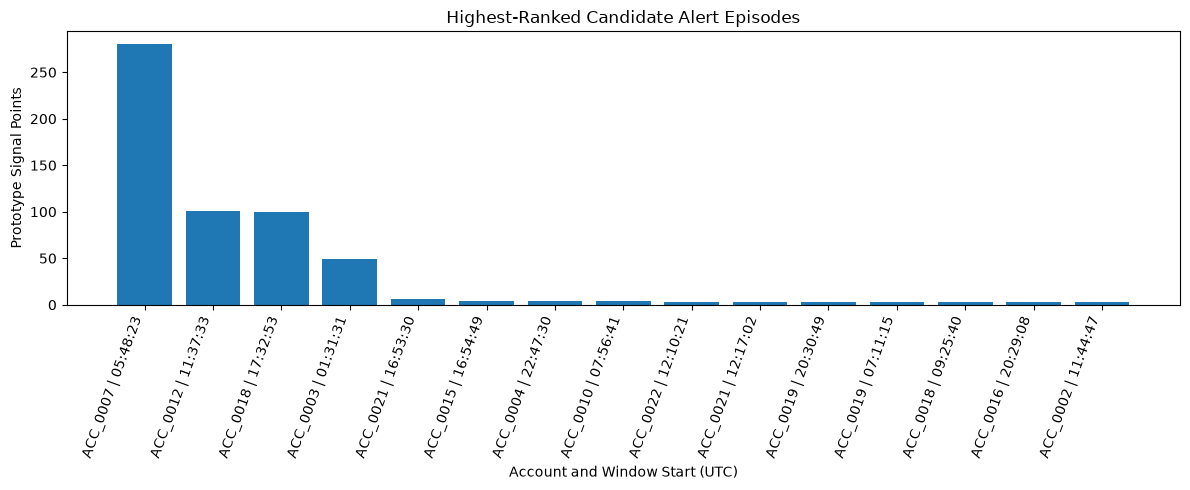

In [49]:
# CELL 30: Visualize consolidated alert episodes

import matplotlib.pyplot as plt

if not consolidated_alerts.empty:
    chart_data = (
        consolidated_alerts
        .sort_values("signal_points", ascending=False)
        .head(15)
        .copy()
    )

    chart_data["alert_label"] = (
        chart_data["account_id"].astype(str)
        + " | "
        + chart_data["window_start"].astype(str).str.slice(11, 19)
    )

    plt.figure(figsize=(12, 5))
    plt.bar(
        chart_data["alert_label"],
        chart_data["signal_points"]
    )
    plt.title("Highest-Ranked Candidate Alert Episodes")
    plt.xlabel("Account and Window Start (UTC)")
    plt.ylabel("Prototype Signal Points")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No consolidated episodes available to plot.")

In [50]:
# CELL 31: Account-level comparison with ground truth

known_accounts = set(
    ground_truth["target_account"].dropna().astype(str)
)

alert_accounts = set(
    consolidated_alerts["account_id"].dropna().astype(str)
)

all_accounts = sorted(known_accounts | alert_accounts)

evaluation = pd.DataFrame({
    "account_id": all_accounts
})

evaluation["known_incident_account"] = (
    evaluation["account_id"].isin(known_accounts)
)

evaluation["candidate_alert_generated"] = (
    evaluation["account_id"].isin(alert_accounts)
)

evaluation["evaluation_result"] = evaluation.apply(
    lambda row: (
        "Known incident account alerted"
        if row["known_incident_account"] and row["candidate_alert_generated"]
        else "Known incident account missed"
        if row["known_incident_account"]
        else "Additional candidate alert"
    ),
    axis=1
)

display(evaluation)

print("\nEvaluation summary:")
display(
    evaluation["evaluation_result"]
    .value_counts()
    .rename_axis("Result")
    .to_frame("Count")
)

,account_id,known_incident_account,candidate_alert_generated,evaluation_result
0,ACC_0002,False,True,Additional candidate alert
1,ACC_0003,True,True,Known incident account alerted
2,ACC_0004,False,True,Additional candidate alert
3,ACC_0005,False,True,Additional candidate alert
4,ACC_0006,False,True,Additional candidate alert
5,ACC_0007,True,True,Known incident account alerted
6,ACC_0010,False,True,Additional candidate alert
7,ACC_0011,False,True,Additional candidate alert
8,ACC_0012,True,True,Known incident account alerted
9,ACC_0013,False,True,Additional candidate alert



Evaluation summary:


,Count
Result,
Additional candidate alert,13
Known incident account alerted,4


In [51]:
# CELL 32: Compare alert evidence against incident descriptions

for _, incident in ground_truth.iterrows():
    account = str(incident["target_account"])

    print("\n" + "=" * 65)
    print("INCIDENT:", incident["incident_id"])
    print("SCENARIO:", incident["scenario_name"])
    print("TARGET ACCOUNT:", account)
    print("DESCRIPTION:", incident["description"])

    account_alerts = consolidated_alerts[
        consolidated_alerts["account_id"].astype(str) == account
    ]

    if account_alerts.empty:
        print("RESULT: No candidate alert for this account")
    else:
        print("Candidate alert episodes:", len(account_alerts))
        display(
            account_alerts[
                [
                    "account_id",
                    "window_start",
                    "window_end",
                    "event_count",
                    "source_count",
                    "signal_points",
                    "signal_types",
                ]
            ]
        )


INCIDENT: INC-2026-001
SCENARIO: Coordinated Credential Stuffing & High-Value Drain
TARGET ACCOUNT: ACC_0003
DESCRIPTION: Failed logins followed by new device login, beneficiary addition, high-value transfer, and log export.
Candidate alert episodes: 1


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types
2,ACC_0003,2026-10-17 01:31:31+00:00,2026-10-17 02:38:00+00:00,23,3,49,"AUDIT_LOG_EXPORT, HIGH_FAILED_LOGINS, HIGH_VAL..."



INCIDENT: INC-2026-002
SCENARIO: API Key Compromise & Bulk Resource Data Exfiltration
TARGET ACCOUNT: ACC_0007
DESCRIPTION: Unusual API key usage, rapid 429 rate limit spikes, followed by bulk downloading of sensitive PDF documents.
Candidate alert episodes: 1


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types
7,ACC_0007,2026-10-17 05:48:23+00:00,2026-10-17 06:33:57+00:00,120,2,280,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED"



INCIDENT: INC-2026-003
SCENARIO: Privilege Escalation & Malicious Beneficiary Transfer
TARGET ACCOUNT: ACC_0012
DESCRIPTION: Late night/off-hours login, role elevation API request, multiple rapid micro-transactions, and session destruction.
Candidate alert episodes: 2


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types
11,ACC_0012,2026-10-17 09:03:01+00:00,2026-10-17 09:33:01+00:00,3,2,3,ISOLATED_ANOMALY
12,ACC_0012,2026-10-17 11:37:33+00:00,2026-10-17 12:38:00+00:00,51,4,101,"ANOMALOUS_PATTERN, ISOLATED_ANOMALY"



INCIDENT: INC-2026-004
SCENARIO: Geographic Anomaly & Rapid Resource Tampering
TARGET ACCOUNT: ACC_0018
DESCRIPTION: Login from US-EAST followed 5 minutes later by login from AP-SOUTH, modified transaction settings, and resource deletion.
Candidate alert episodes: 2


,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types
17,ACC_0018,2026-10-17 09:25:40+00:00,2026-10-17 09:55:40+00:00,3,2,3,ISOLATED_ANOMALY
18,ACC_0018,2026-10-17 17:32:53+00:00,2026-10-17 18:38:00+00:00,50,4,100,ANOMALOUS_PATTERN


In [52]:
# CELL 33: Incident-level evidence summary

incident_evidence = []

for _, incident in ground_truth.iterrows():
    account = str(incident["target_account"])
    incident_id = incident["incident_id"]

    account_events = correlation_events[
        correlation_events["account_id"].astype(str) == account
    ].copy()

    # Inspect only events near the incident's documented start time.
    start_time = pd.to_datetime(
        incident["start_time"], utc=True, errors="coerce"
    )

    if pd.notna(start_time):
        start_time = start_time.floor("min")
        end_time = start_time + pd.Timedelta(minutes=30)

        window_events = account_events[
            (account_events["timestamp"] >= start_time)
            & (account_events["timestamp"] <= end_time)
        ]
    else:
        window_events = account_events.iloc[0:0]

    signal_events = window_events[
        window_events["signal_points"] > 0
    ]

    incident_evidence.append({
        "incident_id": incident_id,
        "scenario": incident["scenario_name"],
        "target_account": account,
        "events_in_window": len(window_events),
        "distinct_sources": signal_events["source_system"].nunique(),
        "positive_signal_events": len(signal_events),
        "signal_types": ", ".join(
            sorted(signal_events["risk_indicator"].unique())
        ) if not signal_events.empty else "None"
    })

incident_evidence_df = pd.DataFrame(incident_evidence)

display(incident_evidence_df)

,incident_id,scenario,target_account,events_in_window,distinct_sources,positive_signal_events,signal_types
0,INC-2026-001,Coordinated Credential Stuffing & High-Value D...,ACC_0003,24,3,23,"AUDIT_LOG_EXPORT, HIGH_FAILED_LOGINS, HIGH_VAL..."
1,INC-2026-002,API Key Compromise & Bulk Resource Data Exfilt...,ACC_0007,122,2,120,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED"
2,INC-2026-003,Privilege Escalation & Malicious Beneficiary T...,ACC_0012,56,4,51,"ANOMALOUS_PATTERN, ISOLATED_ANOMALY"
3,INC-2026-004,Geographic Anomaly & Rapid Resource Tampering,ACC_0018,54,4,50,ANOMALOUS_PATTERN


# 6. Execution Summary

This section summarizes the data processed, candidate alert windows generated, consolidated alert episodes, and account-level coverage.

The results describe the behavior of the current rule-based prototype on synthetic data. They should not be interpreted as evidence of real-world detection accuracy or as results from a trained machine-learning model.

In [53]:
# CELL 34: Prototype execution summary

print("=" * 60)
print("SENTINEL-X | LINUXONE EXECUTION SUMMARY")
print("=" * 60)

print("Total input events:", len(events))
print("Known ground-truth incidents:", len(ground_truth))
print("Candidate alert windows:", len(alerts))
print("Consolidated alert episodes:", len(consolidated_alerts))
print("Accounts with candidate alerts:",
      consolidated_alerts["account_id"].nunique()
      if not consolidated_alerts.empty else 0)

print("\nGround-truth account coverage:")
print(
    len(
        set(ground_truth["target_account"].astype(str))
        & set(consolidated_alerts["account_id"].astype(str))
    ),
    "of",
    ground_truth["target_account"].nunique(),
    "known incident accounts had candidate alerts."
)

print("\nImportant limitation:")
print(
    "This is a rule-based correlation prototype. "
    "Account coverage is not equivalent to event-level detection accuracy."
)

SENTINEL-X | LINUXONE EXECUTION SUMMARY
Total input events: 5500
Known ground-truth incidents: 4
Candidate alert windows: 241
Consolidated alert episodes: 25
Accounts with candidate alerts: 17

Ground-truth account coverage:
4 of 4 known incident accounts had candidate alerts.

Important limitation:
This is a rule-based correlation prototype. Account coverage is not equivalent to event-level detection accuracy.


In [54]:
# CELL 35: Save evaluation outputs

output_dir = Path("sentinel_x_results")
output_dir.mkdir(exist_ok=True)

incident_evidence_df.to_csv(
    output_dir / "incident_evidence_summary.csv",
    index=False
)

evaluation.to_csv(
    output_dir / "account_level_evaluation.csv",
    index=False
)

print("Saved evaluation files:")
for file in sorted(output_dir.glob("*.csv")):
    print("-", file.name)

Saved evaluation files:
- account_level_evaluation.csv
- candidate_alert_windows.csv
- consolidated_alert_episodes.csv
- incident_evidence_summary.csv


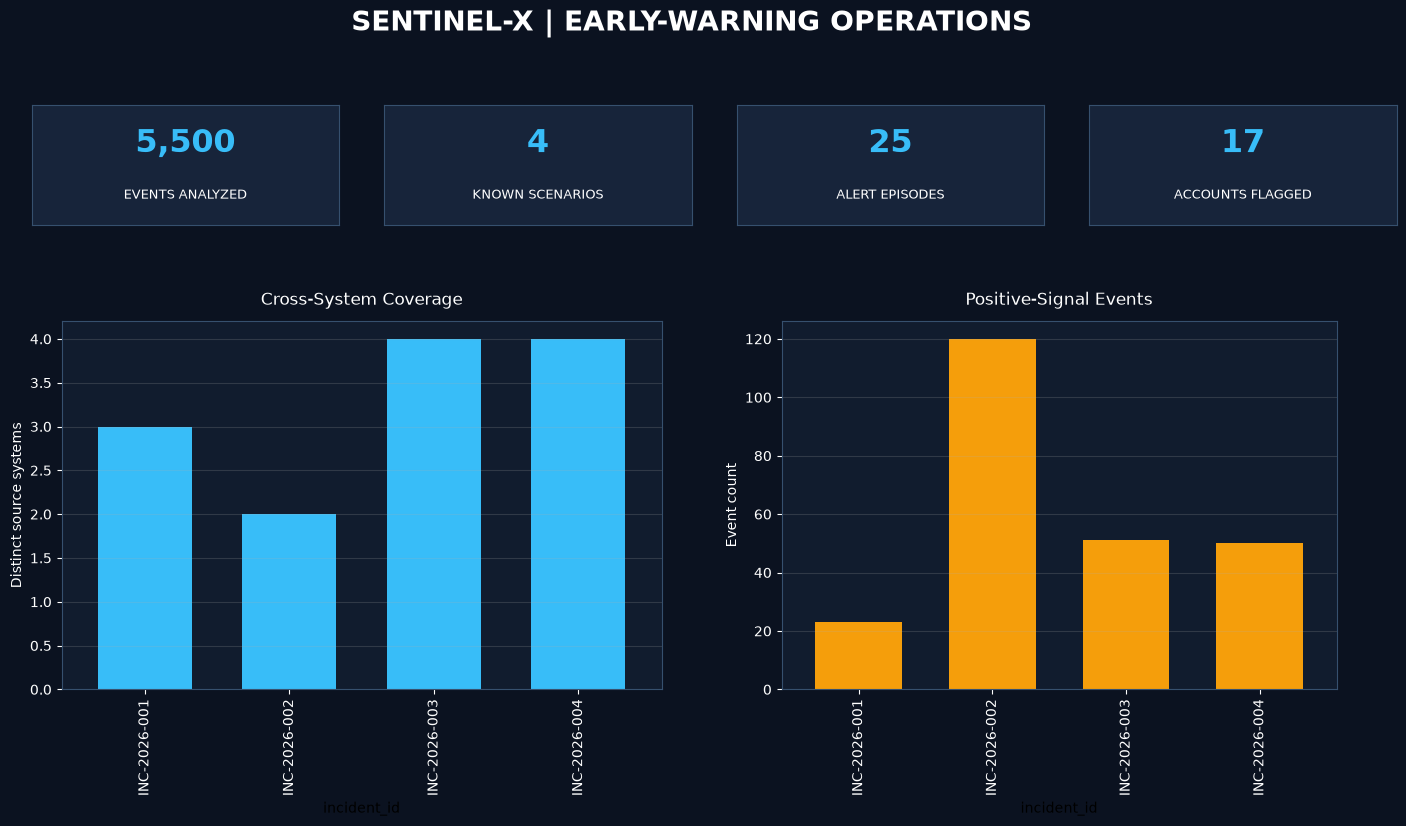

In [60]:
# CELL 36 — SENTINEL-X INCIDENT OVERVIEW

import matplotlib.pyplot as plt
import pandas as pd

# Prepare summary values from existing results
total_events = len(events)
known_incidents = len(ground_truth)
candidate_episodes = len(consolidated_alerts)

accounts_alerted = (
    consolidated_alerts["account_id"].nunique()
    if not consolidated_alerts.empty else 0
)

fig = plt.figure(figsize=(15, 8))
fig.patch.set_facecolor("#0B1220")

# Dashboard title
fig.suptitle(
    "SENTINEL-X | EARLY-WARNING OPERATIONS",
    fontsize=20, fontweight="bold",
    color="white", y=0.97
)

# KPI cards
kpis = [
    ("EVENTS ANALYZED", f"{total_events:,}"),
    ("KNOWN SCENARIOS", str(known_incidents)),
    ("ALERT EPISODES", str(candidate_episodes)),
    ("ACCOUNTS FLAGGED", str(accounts_alerted)),
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_axes([0.06 + i * 0.235, 0.70, 0.205, 0.15])
    ax.set_facecolor("#17243A")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#36506E")
    ax.text(0.5, 0.68, value, ha="center", va="center",
            fontsize=23, fontweight="bold", color="#38BDF8")
    ax.text(0.5, 0.25, label, ha="center", va="center",
            fontsize=9, color="white")

# Incident comparison charts
ax1 = fig.add_axes([0.08, 0.12, 0.40, 0.46])
ax1.set_facecolor("#111C2E")

plot_df = incident_evidence_df.set_index("incident_id")

plot_df["distinct_sources"].plot(
    kind="bar", ax=ax1, color="#38BDF8", width=0.65
)
ax1.set_title("Cross-System Coverage", color="white", pad=12)
ax1.set_ylabel("Distinct source systems", color="white")
ax1.tick_params(colors="white", axis="both")
ax1.spines[:].set_color("#36506E")
ax1.grid(axis="y", alpha=0.2)

ax2 = fig.add_axes([0.56, 0.12, 0.37, 0.46])
ax2.set_facecolor("#111C2E")

plot_df["positive_signal_events"].plot(
    kind="bar", ax=ax2, color="#F59E0B", width=0.65
)
ax2.set_title("Positive-Signal Events", color="white", pad=12)
ax2.set_ylabel("Event count", color="white")
ax2.tick_params(colors="white", axis="both")
ax2.spines[:].set_color("#36506E")
ax2.grid(axis="y", alpha=0.2)

plt.show()

,Signal Type,Count
0,ISOLATED_ANOMALY,550
1,ANOMALOUS_PATTERN,100
2,RATE_LIMIT_EXCEEDED,80
3,BULK_DATA_DOWNLOAD,40
4,HIGH_FAILED_LOGINS,15
5,AUDIT_LOG_EXPORT,5
6,NEW_DEVICE_AFTER_FAILURES,1
7,NEW_BENEFICIARY_ADDED,1
8,HIGH_VALUE_OUTFLOW,1


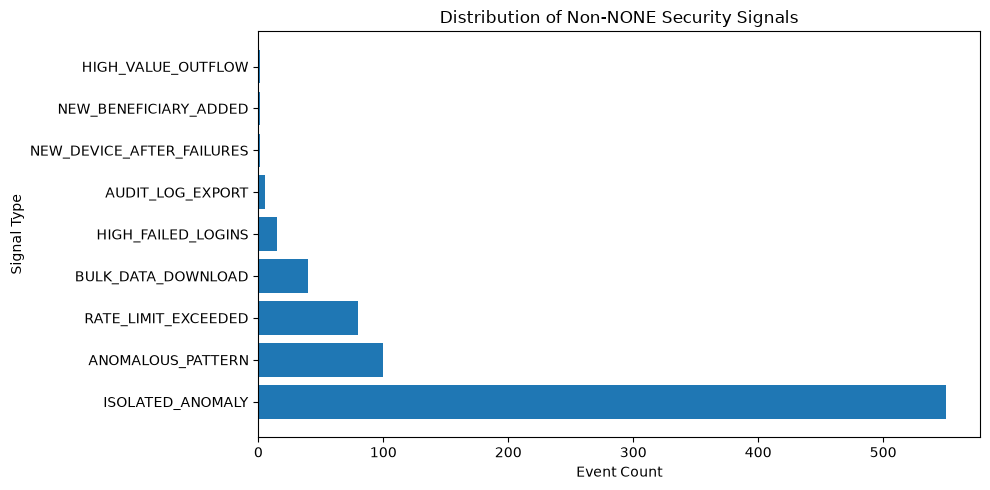

In [56]:
# CELL 37: Inspect signal types in the dataset

signal_counts = (
    events.loc[
        events["risk_indicator"].astype(str).str.upper() != "NONE",
        "risk_indicator"
    ]
    .value_counts()
    .rename_axis("Signal Type")
    .reset_index(name="Count")
)

display(signal_counts)

plt.figure(figsize=(10, 5))
plt.barh(
    signal_counts["Signal Type"],
    signal_counts["Count"]
)
plt.title("Distribution of Non-NONE Security Signals")
plt.xlabel("Event Count")
plt.ylabel("Signal Type")
plt.tight_layout()
plt.show()

# 7. Conclusion and Future Improvements

The notebook demonstrates a LinuxONE-executed prototype for analyzing synthetic cybersecurity events and correlating suspicious activity across multiple source systems.

Current Capabilities

- Multi-source CSV loading and validation
- Exploratory event and signal analysis
- Heuristic signal scoring
- Time-window correlation by account
- Candidate-alert consolidation
- Evidence inspection and ground-truth comparison

Future Improvements

- Integrate and validate the complete application detection modules
- Refine event and incident matching to reduce false positives
- Evaluate precision, recall, and other suitable metrics
- Add a dashboard for interactive incident investigation
- Test a trained machine-learning model if justified by the dataset and project requirements

Final note: The current implementation is a rule-based correlation prototype. Further validation is needed before making claims about production readiness or predictive performance.

In [57]:
# CELL 38: Export final evidence tables

from pathlib import Path

output_dir = Path("sentinel_x_results")
output_dir.mkdir(exist_ok=True)

incident_evidence_df.to_csv(
    output_dir / "incident_evidence_summary.csv",
    index=False
)

signal_counts.to_csv(
    output_dir / "security_signal_distribution.csv",
    index=False
)

print("Evidence saved in:", output_dir.resolve())

for file in sorted(output_dir.glob("*.csv")):
    print(file.name, "-", file.stat().st_size, "bytes")

Evidence saved in: /home/ibm-user/sentinel_x_results
account_level_evaluation.csv - 889 bytes
candidate_alert_windows.csv - 141262 bytes
consolidated_alert_episodes.csv - 6267 bytes
incident_evidence_summary.csv - 639 bytes
security_signal_distribution.csv - 220 bytes


In [58]:
# CELL 39: Final validation checklist

checks = {
    "Master dataset loaded": "events" in globals() and len(events) > 0,
    "Four known incidents loaded": (
        "ground_truth" in globals() and len(ground_truth) == 4
    ),
    "Correlation prototype executed": "alerts" in globals(),
    "Consolidated results generated": "consolidated_alerts" in globals(),
    "Incident evidence generated": "incident_evidence_df" in globals(),
    "Signal distribution generated": "signal_counts" in globals(),
}

print("=" * 55)
print("SENTINEL-X — FINAL VALIDATION")
print("=" * 55)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} | {name}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("Architecture:", platform.machine())

SENTINEL-X — FINAL VALIDATION
PASS | Master dataset loaded
PASS | Four known incidents loaded
PASS | Correlation prototype executed
PASS | Consolidated results generated
PASS | Incident evidence generated
PASS | Signal distribution generated

Passed: 6 / 6
Architecture: s390x


# 8. Cross-System Correlation Map

### This visualization shows how suspicious events connect accounts to multiple source systems. It provides an investigation view of the relationships observed in the synthetic dataset.

Connections represent observed events, not proof that every connected event belongs to the same real-world attack.

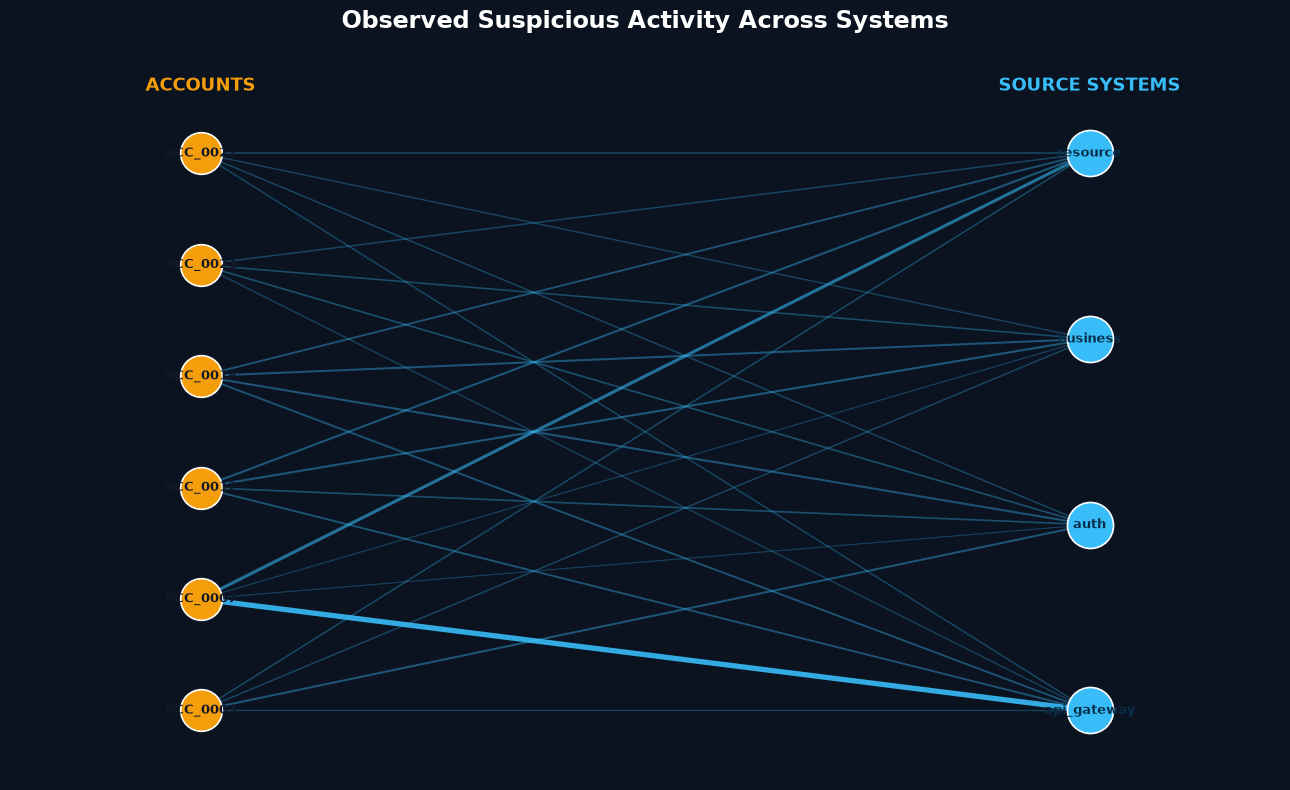

Accounts displayed: 6
Source systems displayed: 4
Observed account-system connections: 24


In [61]:
# CELL 40 — ACCOUNT-TO-SYSTEM CORRELATION MAP

import matplotlib.pyplot as plt
import numpy as np

positive = correlation_events[
    pd.to_numeric(
        correlation_events["signal_points"], errors="coerce"
    ).fillna(0) > 0
].copy()

# Select the most active accounts by signal points
top_accounts = (
    positive.groupby("account_id")["signal_points"]
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index.astype(str).tolist()
)

map_data = positive[
    positive["account_id"].astype(str).isin(top_accounts)
].copy()

systems = sorted(map_data["source_system"].dropna().unique().astype(str))
accounts = sorted(map_data["account_id"].dropna().unique().astype(str))

fig, ax = plt.subplots(figsize=(13, 8))
fig.patch.set_facecolor("#0B1220")
ax.set_facecolor("#0B1220")

# Put account nodes on the left and systems on the right
left_y = np.linspace(0.1, 0.9, max(len(accounts), 2))
right_y = np.linspace(0.1, 0.9, max(len(systems), 2))

account_pos = {
    account: (0.15, left_y[i])
    for i, account in enumerate(accounts)
}
system_pos = {
    system: (0.85, right_y[i])
    for i, system in enumerate(systems)
}

# Draw connections weighted by the number of observed events
edges = (
    map_data.groupby(["account_id", "source_system"])
    .size().reset_index(name="event_count")
)

max_count = max(edges["event_count"].max(), 1)

for _, edge in edges.iterrows():
    account = str(edge["account_id"])
    system = str(edge["source_system"])

    if account not in account_pos or system not in system_pos:
        continue

    x1, y1 = account_pos[account]
    x2, y2 = system_pos[system]

    ax.plot(
        [x1, x2], [y1, y2],
        color="#38BDF8",
        alpha=0.25 + 0.65 * edge["event_count"] / max_count,
        linewidth=0.8 + 3 * edge["event_count"] / max_count,
        zorder=1
    )

for account, (x, y) in account_pos.items():
    ax.scatter(x, y, s=900, color="#F59E0B",
               edgecolors="white", linewidths=1.2, zorder=3)
    ax.text(x, y, account, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#111827", zorder=4)

for system, (x, y) in system_pos.items():
    ax.scatter(x, y, s=1100, color="#38BDF8",
               edgecolors="white", linewidths=1.2, zorder=3)
    ax.text(x, y, system, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#082F49", zorder=4)

ax.text(0.15, 0.99, "ACCOUNTS", color="#F59E0B",
        fontsize=13, fontweight="bold", ha="center")
ax.text(0.85, 0.99, "SOURCE SYSTEMS", color="#38BDF8",
        fontsize=13, fontweight="bold", ha="center")

ax.set_title(
    "Observed Suspicious Activity Across Systems",
    color="white", fontsize=17, fontweight="bold", pad=20
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.04)
ax.axis("off")

plt.tight_layout()
plt.show()

print("Accounts displayed:", len(accounts))
print("Source systems displayed:", len(systems))
print("Observed account-system connections:", len(edges))

# 9. Incident Timeline

#### The timeline displays positive-signal events associated with a known incident account. It helps investigators inspect when signals appeared and which systems and event types produced them.

,incident_id,target_account,scenario_name
0,INC-2026-001,ACC_0003,Coordinated Credential Stuffing & High-Value D...
1,INC-2026-002,ACC_0007,API Key Compromise & Bulk Resource Data Exfilt...
2,INC-2026-003,ACC_0012,Privilege Escalation & Malicious Beneficiary T...
3,INC-2026-004,ACC_0018,Geographic Anomaly & Rapid Resource Tampering


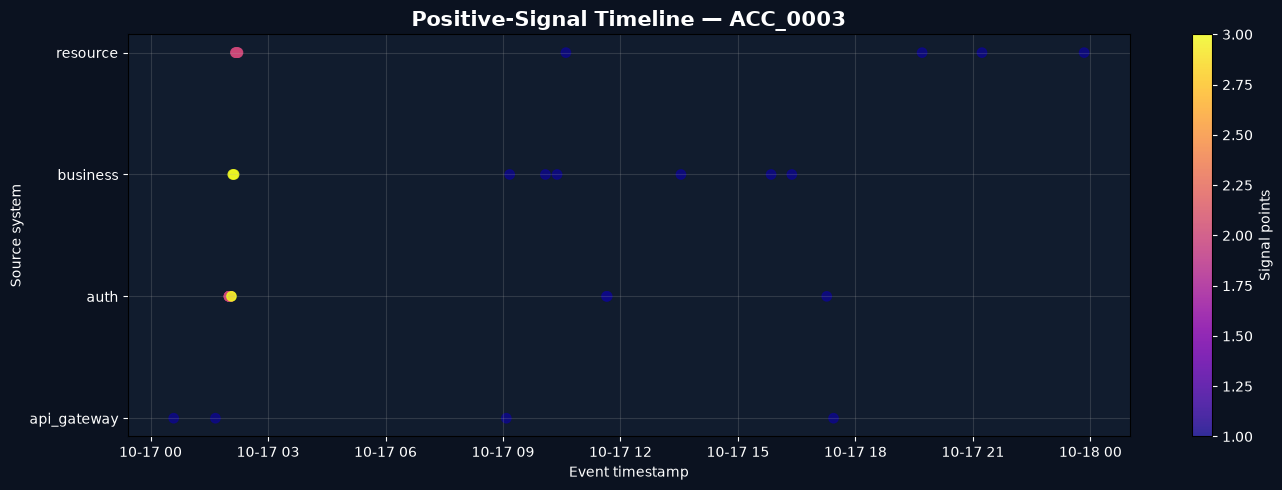

Scenario: Coordinated Credential Stuffing & High-Value Drain
Account: ACC_0003
Positive-signal events plotted: 40


,timestamp,source_system,event_type,risk_indicator,signal_points
123,2026-10-17 00:35:28+00:00,api_gateway,transaction_rejected,ISOLATED_ANOMALY,1
349,2026-10-17 01:39:25+00:00,api_gateway,login_failure,ISOLATED_ANOMALY,1
424,2026-10-17 02:00:00+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
425,2026-10-17 02:00:12+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
426,2026-10-17 02:00:24+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
428,2026-10-17 02:00:36+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
429,2026-10-17 02:00:48+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
430,2026-10-17 02:01:00+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
433,2026-10-17 02:01:12+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2
434,2026-10-17 02:01:24+00:00,auth,login_failure,HIGH_FAILED_LOGINS,2


In [62]:
# CELL 41 — KNOWN INCIDENT TIMELINE

from IPython.display import display

incident_options = ground_truth[
    ["incident_id", "target_account", "scenario_name"]
].drop_duplicates()

display(incident_options)

# Default to the first documented incident
selected_incident = ground_truth.iloc[0]
selected_account = str(selected_incident["target_account"])

timeline = correlation_events[
    correlation_events["account_id"].astype(str) == selected_account
].copy()

timeline["timestamp"] = pd.to_datetime(
    timeline["timestamp"], utc=True, errors="coerce"
)

timeline["signal_points"] = pd.to_numeric(
    timeline["signal_points"], errors="coerce"
).fillna(0)

timeline = timeline[
    (timeline["signal_points"] > 0)
    & timeline["timestamp"].notna()
].sort_values("timestamp")

fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor("#0B1220")
ax.set_facecolor("#111C2E")

if not timeline.empty:
    systems = timeline["source_system"].astype(str)
    system_codes, system_names = pd.factorize(systems)

    scatter = ax.scatter(
        timeline["timestamp"],
        system_codes,
        c=timeline["signal_points"],
        cmap="plasma",
        s=45,
        alpha=0.85
    )

    ax.set_yticks(range(len(system_names)))
    ax.set_yticklabels(system_names, color="white")
    ax.set_xlabel("Event timestamp", color="white")
    ax.set_ylabel("Source system", color="white")
    ax.tick_params(colors="white")

    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Signal points", color="white")
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(cbar.ax.get_yticklabels(), color="white")

    ax.set_title(
        f"Positive-Signal Timeline — {selected_account}",
        color="white", fontsize=15, fontweight="bold"
    )
    ax.grid(alpha=0.2)
else:
    ax.text(
        0.5, 0.5, "No positive-signal events found for this account",
        color="white", ha="center", va="center"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scenario:", selected_incident["scenario_name"])
print("Account:", selected_account)
print("Positive-signal events plotted:", len(timeline))

display(
    timeline[
        ["timestamp", "source_system", "event_type",
         "risk_indicator", "signal_points"]
    ].head(25)
)

# 10. Alert Investigation Panel

#### This section summarizes the strongest available candidate-alert evidence for an account. It is intended to support investigation, not to automatically declare an account compromised.

In [63]:
# CELL 42 — ALERT INVESTIGATION PANEL

if consolidated_alerts.empty:
    print("No consolidated candidate alerts are available.")
else:
    ranked = consolidated_alerts.copy()

    ranked["signal_points"] = pd.to_numeric(
        ranked["signal_points"], errors="coerce"
    ).fillna(0)

    ranked = ranked.sort_values(
        "signal_points", ascending=False
    )

    display(
        ranked.head(10)
    )

    strongest = ranked.iloc[0]
    account = str(strongest["account_id"])

    evidence = correlation_events[
        correlation_events["account_id"].astype(str) == account
    ].copy()

    evidence["signal_points"] = pd.to_numeric(
        evidence["signal_points"], errors="coerce"
    ).fillna(0)

    evidence = evidence[evidence["signal_points"] > 0]

    print("=" * 60)
    print("CANDIDATE ALERT INVESTIGATION")
    print("=" * 60)
    print("Account:", account)
    print("Signal points in account evidence:",
          int(evidence["signal_points"].sum()))
    print("Positive-signal events:", len(evidence))
    print("Distinct source systems:",
          evidence["source_system"].nunique())
    print("Signal types:",
          ", ".join(sorted(
              evidence["risk_indicator"].dropna().astype(str).unique()
          )))

    display(
        evidence[
            ["timestamp", "source_system", "event_type",
             "risk_indicator", "signal_points"]
        ].head(20)
    )

,account_id,window_start,window_end,event_count,source_count,signal_points,signal_types,event_ids
7,ACC_0007,2026-10-17 05:48:23+00:00,2026-10-17 06:33:57+00:00,120,2,280,"BULK_DATA_DOWNLOAD, RATE_LIMIT_EXCEEDED","EVT-100024, EVT-100025, EVT-100026, EVT-100027..."
12,ACC_0012,2026-10-17 11:37:33+00:00,2026-10-17 12:38:00+00:00,51,4,101,"ANOMALOUS_PATTERN, ISOLATED_ANOMALY","EVT-100144, EVT-100145, EVT-100146, EVT-100147..."
18,ACC_0018,2026-10-17 17:32:53+00:00,2026-10-17 18:38:00+00:00,50,4,100,ANOMALOUS_PATTERN,"EVT-100194, EVT-100195, EVT-100196, EVT-100197..."
2,ACC_0003,2026-10-17 01:31:31+00:00,2026-10-17 02:38:00+00:00,23,3,49,"AUDIT_LOG_EXPORT, HIGH_FAILED_LOGINS, HIGH_VAL...","EVT-100001, EVT-100002, EVT-100003, EVT-100004..."
22,ACC_0021,2026-10-17 16:53:30+00:00,2026-10-17 17:54:44+00:00,6,3,6,ISOLATED_ANOMALY,"EVT-100498, EVT-100502, EVT-100510, EVT-100623..."
15,ACC_0015,2026-10-17 16:54:49+00:00,2026-10-17 17:45:13+00:00,4,3,4,ISOLATED_ANOMALY,"EVT-100377, EVT-100452, EVT-100476, EVT-100538"
3,ACC_0004,2026-10-17 22:47:30+00:00,2026-10-17 23:43:26+00:00,4,4,4,ISOLATED_ANOMALY,"EVT-100294, EVT-100307, EVT-100337, EVT-100352..."
8,ACC_0010,2026-10-17 07:56:41+00:00,2026-10-17 08:50:27+00:00,4,3,4,ISOLATED_ANOMALY,"EVT-100276, EVT-100460, EVT-100653, EVT-100680..."
23,ACC_0022,2026-10-17 12:10:21+00:00,2026-10-17 12:40:21+00:00,3,3,3,ISOLATED_ANOMALY,"EVT-100591, EVT-100260, EVT-100781"
21,ACC_0021,2026-10-17 12:17:02+00:00,2026-10-17 13:03:49+00:00,3,3,3,ISOLATED_ANOMALY,"EVT-100290, EVT-100345, EVT-100386, EVT-100792"


CANDIDATE ALERT INVESTIGATION
Account: ACC_0007
Signal points in account evidence: 291
Positive-signal events: 131
Distinct source systems: 4
Signal types: BULK_DATA_DOWNLOAD, ISOLATED_ANOMALY, RATE_LIMIT_EXCEEDED


,timestamp,source_system,event_type,risk_indicator,signal_points
27,2026-10-17 00:06:35+00:00,auth,login_failure,ISOLATED_ANOMALY,1
301,2026-10-17 01:27:09+00:00,business,login_failure,ISOLATED_ANOMALY,1
422,2026-10-17 01:59:40+00:00,api_gateway,transaction_rejected,ISOLATED_ANOMALY,1
538,2026-10-17 02:29:52+00:00,business,transaction_rejected,ISOLATED_ANOMALY,1
950,2026-10-17 04:16:26+00:00,api_gateway,resource_permission_denied,ISOLATED_ANOMALY,1
1332,2026-10-17 06:00:00+00:00,api_gateway,api_request,RATE_LIMIT_EXCEEDED,2
1333,2026-10-17 06:00:03+00:00,api_gateway,api_request,RATE_LIMIT_EXCEEDED,2
1334,2026-10-17 06:00:06+00:00,api_gateway,api_request,RATE_LIMIT_EXCEEDED,2
1335,2026-10-17 06:00:09+00:00,api_gateway,api_request,RATE_LIMIT_EXCEEDED,2
1336,2026-10-17 06:00:12+00:00,api_gateway,api_request,RATE_LIMIT_EXCEEDED,2
